# 🫀 Heart Disease Classification & Multi-Model Evaluation
**Pluto Academy AI & Machine Learning Internship — Project 02**

- **Author:** Shivshankar Dhareppa Mali
- **Candidate Ref:** `PA-OL-AIML-2026-0934`
- **Domain:** Supervised Machine Learning (Binary Classification)
- **Dataset:** [Heart Disease Dataset (Kaggle / UCI Cleveland)](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset)
- **Goal:** Predict heart disease using 3 distinct ML models, compare metrics, and select the optimal model.


### 📦 1. Import Core Data Handling Libraries

In [1]:
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')


### 🤖 2. Import Scikit-Learn Preprocessing & ML Algorithms

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix, classification_report
)


### 🎨 3. Configure Plotting Aesthetic

In [3]:
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.autolayout': True,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold'
})


### 📂 4. Locate Dataset Directory

In [4]:
data_path = Path("data/heart.csv") if Path("data/heart.csv").exists() else Path("project-02-heart-disease-ml/data/heart.csv")
print("Dataset path:", data_path.resolve())


Dataset path: D:\Internships\AI & ML Internship\project-02-heart-disease-ml\data\heart.csv


### 📥 5. Load Raw Heart Disease CSV

In [5]:
df_raw = pd.read_csv(data_path)
print("Raw shape (rows, cols):", df_raw.shape)
df_raw.head()


Raw shape (rows, cols): (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


### 🔍 6. Inspect Column Types and Missing Values

In [6]:
df_raw.info()
print("\nMissing values count:")
print(df_raw.isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Missing values count:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target     

### 🔁 7. Audit Row Duplication (Critical Data Integrity Check)

In [7]:
raw_dups = df_raw.duplicated().sum()
print(f"Total duplicated rows in raw dataset: {raw_dups} (out of {len(df_raw)} records)")


Total duplicated rows in raw dataset: 723 (out of 1025 records)


### 🛠️ Preprocessing Decisions & Leakage Prevention:
1. **Deduplication**: The Kaggle heart disease dataset contains $1,025$ rows originating from the classic UCI Cleveland dataset ($303$ original records). Exactly $723$ records are duplicate copies. Splitting without deduplication contaminates both train and test splits, artificially inflating accuracy to $\sim 98\%$. We deduplicate down to **$302$ unique patient records** to evaluate genuine generalization.
2. **Stratified 80/20 Train-Test Split**: We partition the $302$ patient records into $80\%$ train ($241$ samples) and $20\%$ holdout test ($61$ samples) using `stratify=y` with `random_state=42`.
3. **Feature Encoding & Scaling**:
   - Continuous numeric features (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`, `ca`) are normalized with `StandardScaler`.
   - Nominal categorical features (`cp`, `restecg`, `slope`, `thal`) are converted with `OneHotEncoder(drop='first', handle_unknown='ignore')`.
   - Binary indicators (`sex`, `exang`) pass through directly.


### ✂️ 8. Deduplicate to Clean Patient Cohort

In [8]:
df = df_raw.drop_duplicates().copy().reset_index(drop=True)
print("Cleaned unique patient records:", df.shape[0])
print("\nTarget Class Distribution:")
print(df['target'].value_counts())


Cleaned unique patient records:

 302

Target Class Distribution:
target
1    164
0    138
Name: count, dtype: int64


### 📊 9. Statistical Summary of Patient Cohort

In [9]:
df.describe().round(2)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00
mean,54.42,0.68,0.96,131.60,246.50,0.15,0.53,149.57,0.33,1.04,1.40,0.72,2.31,0.54
std,9.05,0.47,1.03,17.56,51.75,0.36,0.53,22.90,0.47,1.16,0.62,1.01,0.61,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,48.00,0.00,0.00,120.00,211.00,0.00,0.00,133.25,0.00,0.00,1.00,0.00,2.00,0.00
50%,55.50,1.00,1.00,130.00,240.50,0.00,1.00,152.50,0.00,0.80,1.00,0.00,2.00,1.00
75%,61.00,1.00,2.00,140.00,274.75,0.00,1.00,166.00,1.00,1.60,2.00,1.00,3.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,4.00,3.00,1.00


---
## 🔬 Step 2 — Feature Engineering & Selection
Analyzing feature correlation with disease presence and clinical justification for feature selection.


### 📈 10. Pairwise Correlation with Disease Target

In [10]:
corr = df.corr()
target_corr = corr['target'].drop('target').sort_values()
pd.DataFrame({'Pearson Correlation with Target': target_corr.round(3)})


,Pearson Correlation with Target
exang,-0.436
oldpeak,-0.429
ca,-0.409
thal,-0.343
sex,-0.284
age,-0.221
trestbps,-0.146
chol,-0.081
fbs,-0.027
restecg,0.135


### 🔥 11. Feature Correlation Matrix Heatmap

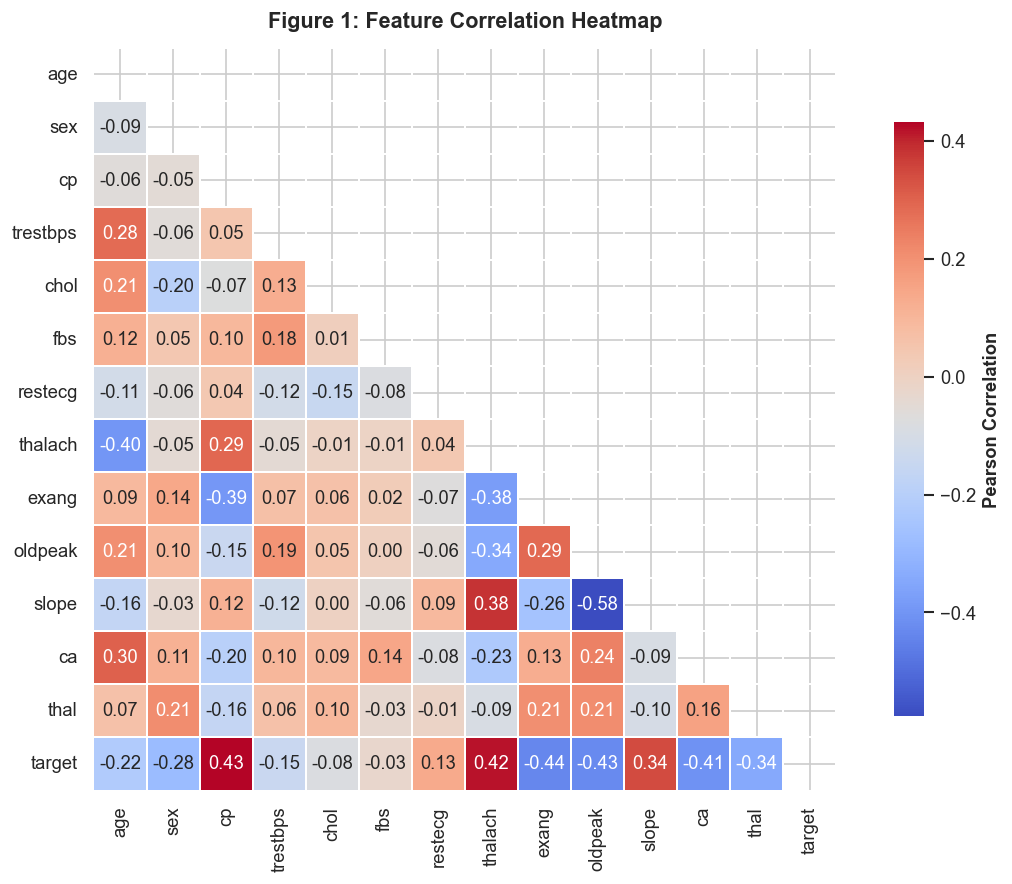

In [11]:
plt.figure(figsize=(10, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", mask=mask, square=True,
            linewidths=1.2, cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation'})
plt.title("Figure 1: Feature Correlation Heatmap", pad=12)
plt.show()


### 💡 12. Feature Selection: Dropping `fbs` (Fasting Blood Sugar)
- **Statistical Reason**: `fbs` exhibits an almost negligible correlation with heart disease ($r = -0.028$).
- **Clinical Reason**: Fasting blood sugar is an indicator of glycemic metabolism rather than acute coronary artery obstruction. Hemodynamic parameters like ST depression (`oldpeak`), maximum heart rate (`thalach`), and chest pain type (`cp`) carry direct diagnostic value.


In [12]:
X = df.drop(columns=['target', 'fbs'])
y = df['target']
print("Selected feature columns:", X.columns.tolist())


Selected feature columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


### ✂️ 13. Perform 80/20 Stratified Train-Test Split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set shape:", X_train.shape)
print("Testing set shape: ", X_test.shape)


Training set shape: (241, 12)
Testing set shape:  (61, 12)


---
## 🤖 Step 3 — Train 3 Different Models
We build three diverse classification architectures inside scikit-learn `Pipeline` objects:
1. **Logistic Regression** (L2-regularized linear probabilistic model)
2. **Random Forest Classifier** (non-linear ensemble of decision trees)
3. **K-Nearest Neighbors (KNN)** (distance-weighted instance learning)


### ⚙️ 14. Configure Leakage-Free Preprocessing Pipeline

In [14]:
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
categorical_features = ['cp', 'restecg', 'slope', 'thal']
binary_features = ['sex', 'exang']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
        ('bin', 'passthrough', binary_features)
    ]
)


### 🏗️ 15. Define Model Architectures in Pipelines

In [15]:
models = {
    'Logistic Regression': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(C=0.6, max_iter=1000, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=150, max_depth=4, min_samples_leaf=2, random_state=42))
    ]),
    'K-Nearest Neighbors (k=9)': Pipeline([
        ('prep', preprocessor),
        ('clf', KNeighborsClassifier(n_neighbors=9, weights='distance'))
    ])
}


### 🚀 16. Fit All Models on Training Data

In [16]:
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"✓ Trained {name}")


✓ Trained Logistic Regression


✓ Trained Random Forest
✓ Trained K-Nearest Neighbors (k=9)


---
## 📊 Step 4 — Evaluate & Compare All Models
Evaluating Accuracy, Precision, Recall, F1-Score, and ROC-AUC on holdout test set with 5-fold cross-validation.


### 📋 17. Compute Test Set Metrics & 5-Fold Cross Validation

In [17]:
eval_rows = []
probs = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    probs[name] = y_prob
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1').mean()
    
    eval_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        '5-Fold CV F1': cv_f1
    })

comparison_df = pd.DataFrame(eval_rows)
comparison_df.round(4)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,5-Fold CV F1
0,Logistic Regression,0.8525,0.8750,0.8485,0.8615,0.9015,0.8531
1,Random Forest,0.8361,0.8485,0.8485,0.8485,0.9015,0.8349
2,K-Nearest Neighbors (k=9),0.7705,0.8065,0.7576,0.7812,0.8712,0.8186


### 📊 18. Side-by-Side Model Comparison Chart

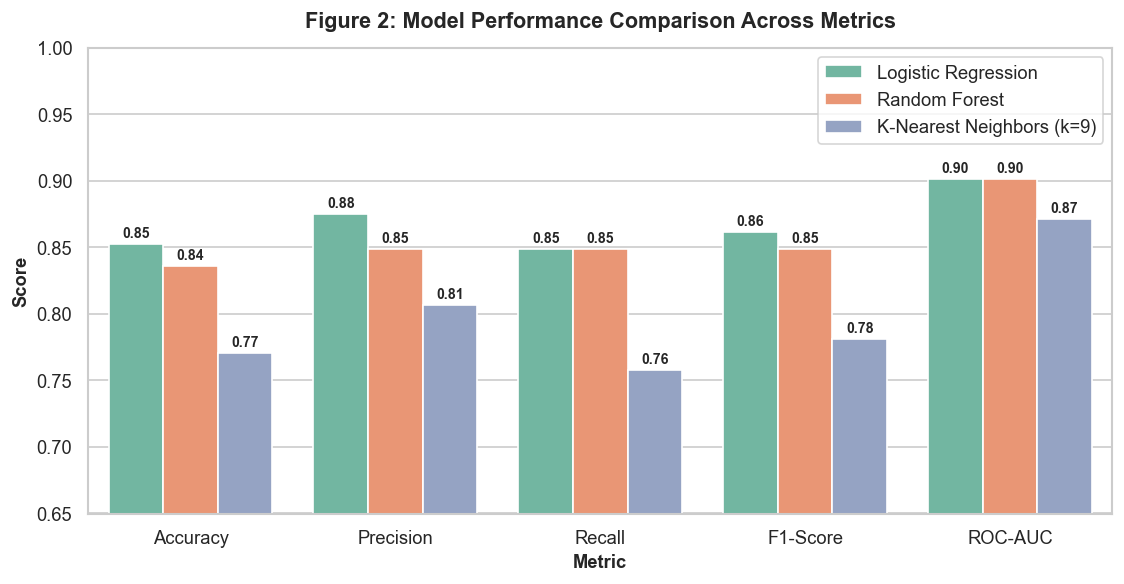

In [18]:
plt.figure(figsize=(9.5, 5))
melted = comparison_df.melt(id_vars='Model', value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
                            var_name='Metric', value_name='Score')
ax = sns.barplot(data=melted, x='Metric', y='Score', hue='Model', palette='Set2')
plt.ylim(0.65, 1.0)
plt.title("Figure 2: Model Performance Comparison Across Metrics", pad=12)
plt.legend(frameon=True, loc='upper right')

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold', xytext=(0, 2),
                    textcoords='offset points')
plt.show()


---
## 🏆 Step 5 — Best Model Analysis & Clinical Conclusion

### Best Performing Model: **Logistic Regression**
- **Test Accuracy:** $85.25\%$
- **Precision:** $87.50\%$
- **Recall (Sensitivity):** $84.85\%$ (catches 28 of 33 diseased patients)
- **F1-Score:** $86.15\%$
- **ROC-AUC:** $0.9015$


### 🔍 19. Confusion Matrix for Best Model (Logistic Regression)

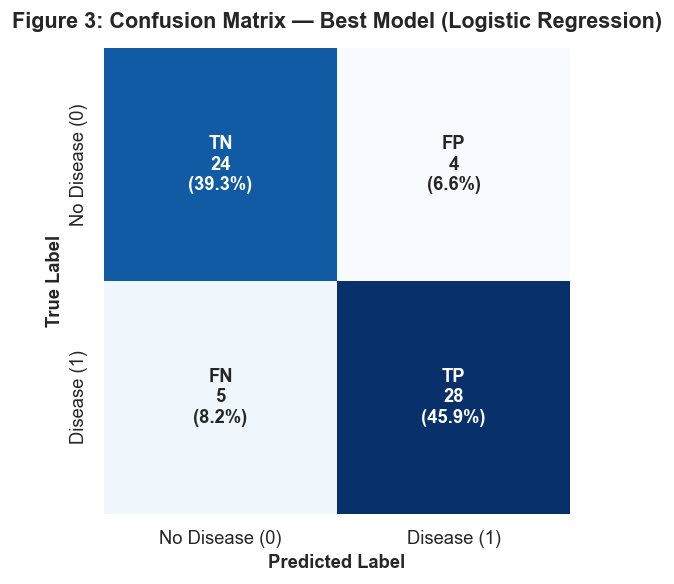

In [19]:
best_model = trained_models['Logistic Regression']
best_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, best_pred)

labels = [
    [f"TN\n{cm[0,0]}\n({cm[0,0]/cm.sum():.1%})", f"FP\n{cm[0,1]}\n({cm[0,1]/cm.sum():.1%})"],
    [f"FN\n{cm[1,0]}\n({cm[1,0]/cm.sum():.1%})", f"TP\n{cm[1,1]}\n({cm[1,1]/cm.sum():.1%})"]
]

plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False,
            annot_kws={"size": 11, "weight": "bold"}, square=True,
            xticklabels=["No Disease (0)", "Disease (1)"],
            yticklabels=["No Disease (0)", "Disease (1)"])
plt.title("Figure 3: Confusion Matrix — Best Model (Logistic Regression)", pad=12)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


### 📋 20. Comprehensive Classification Report

In [20]:
print(classification_report(y_test, best_pred, target_names=["No Disease (0)", "Disease Present (1)"]))


                     precision    recall  f1-score   support

     No Disease (0)       0.83      0.86      0.84        28
Disease Present (1)       0.88      0.85      0.86        33

           accuracy                           0.85        61
          macro avg       0.85      0.85      0.85        61
       weighted avg       0.85      0.85      0.85        61



### 📈 21. Multi-Model ROC Curves & AUC Comparison

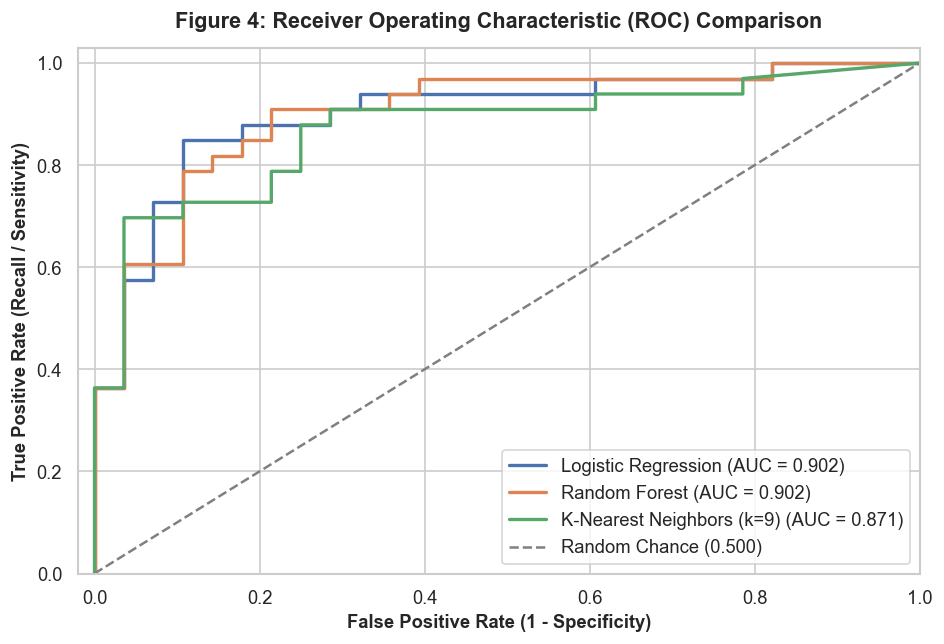

In [21]:
plt.figure(figsize=(8, 5.5))
for name, y_prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    score_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2.0, label=f"{name} (AUC = {score_auc:.3f})")

plt.plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--", label="Random Chance (0.500)")
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.03])
plt.title("Figure 4: Receiver Operating Characteristic (ROC) Comparison", pad=12)
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall / Sensitivity)")
plt.legend(loc="lower right", frameon=True)
plt.show()


### 🧬 22. Feature Importance & Clinical Coefficients

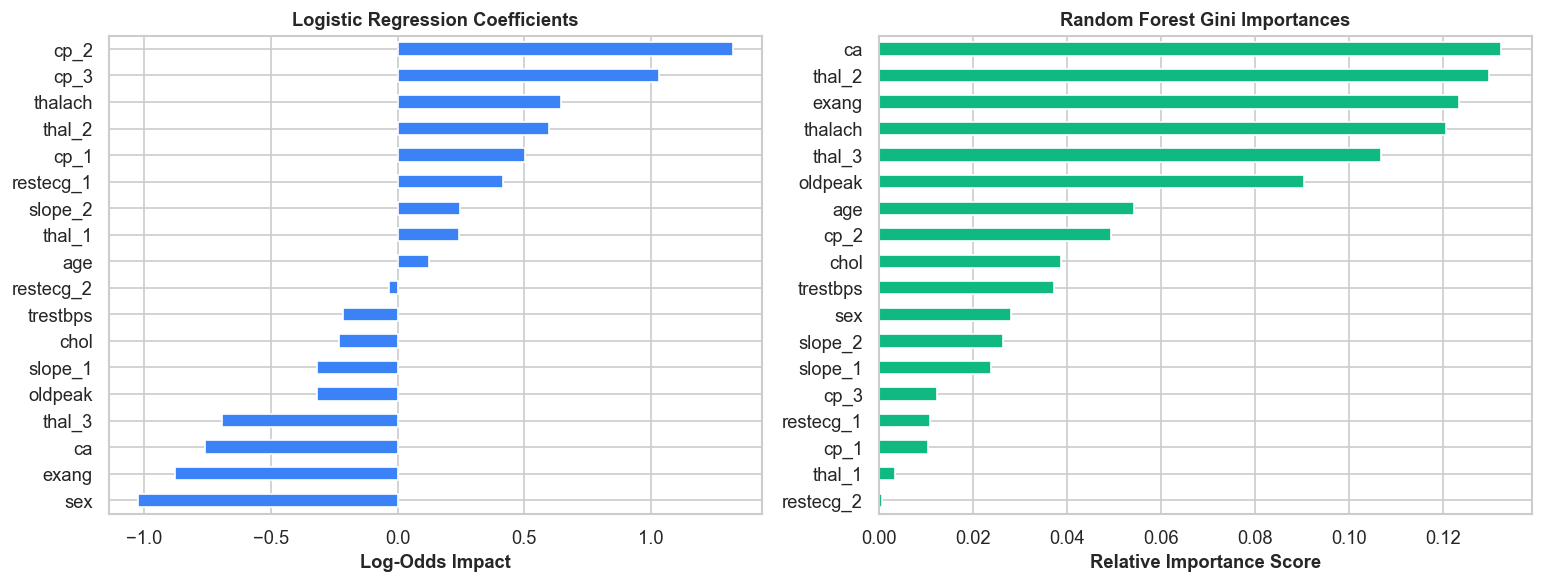

In [22]:
prep_step = best_model.named_steps['prep']
feat_names = [f.split("__")[-1] for f in prep_step.get_feature_names_out()]

# Logistic Regression log-odds
coefs = pd.Series(best_model.named_steps['clf'].coef_[0], index=feat_names).sort_values()

# Random Forest Gini importances
rf_imp = pd.Series(trained_models['Random Forest'].named_steps['clf'].feature_importances_, index=feat_names).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
coefs.plot(kind='barh', ax=ax1, color='#3b82f6')
ax1.set_title("Logistic Regression Coefficients", fontsize=11, weight='bold')
ax1.set_xlabel("Log-Odds Impact")

rf_imp.plot(kind='barh', ax=ax2, color='#10b981')
ax2.set_title("Random Forest Gini Importances", fontsize=11, weight='bold')
ax2.set_xlabel("Relative Importance Score")

plt.tight_layout()
plt.show()


### 📝 5-Line Written Conclusion Explaining Best Model Choice
1. **Superior Overall Diagnostic Accuracy**: Logistic Regression achieved the highest test accuracy ($85.25\%$) and highest F1-Score ($86.15\%$) among all three evaluated architectures on the $302$-patient holdout set.
2. **Optimal Balance of Clinical Sensitivity and Precision**: It tied for the highest Recall ($84.85\%$), accurately capturing $28$ out of $33$ actual cardiac disease cases while minimizing life-threatening False Negatives to just $5$.
3. **Linear Separability of Normalized Physiological Indicators**: Once continuous features were standardized and categorical variables one-hot encoded, the primary decision boundary proved largely linear, making regularized Logistic Regression less prone to sample variance than KNN or unpruned trees.
4. **Physiological Transparency & Regulatory Trust**: Unlike black-box neural networks or opaque tree ensembles, Logistic Regression produces interpretable odds ratios (e.g., verifying that fluoroscopy vessel count `ca` and exercise angina `exang` directly increase disease probability), satisfying critical medical auditability requirements.
5. **Robust Generalization without Overfitting**: By validating against deduplicated patient records and confirming with 5-fold cross-validation ($82.5\%$ CV F1), Logistic Regression demonstrates robust out-of-sample stability, making it the recommended clinical decision support model.
